In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

In [3]:
df = pd.read_csv("kc_house_data.csv")

print(df.head())
print(df.info())

           id             date     price  bedrooms  bathrooms  sqft_living  \
0  7129300520  20141013T000000  221900.0         3       1.00         1180   
1  6414100192  20141209T000000  538000.0         3       2.25         2570   
2  5631500400  20150225T000000  180000.0         2       1.00          770   
3  2487200875  20141209T000000  604000.0         4       3.00         1960   
4  1954400510  20150218T000000  510000.0         3       2.00         1680   

   sqft_lot  floors  waterfront  view  ...  grade  sqft_above  sqft_basement  \
0      5650     1.0           0     0  ...      7        1180              0   
1      7242     2.0           0     0  ...      7        2170            400   
2     10000     1.0           0     0  ...      6         770              0   
3      5000     1.0           0     0  ...      7        1050            910   
4      8080     1.0           0     0  ...      8        1680              0   

   yr_built  yr_renovated  zipcode      lat     lo

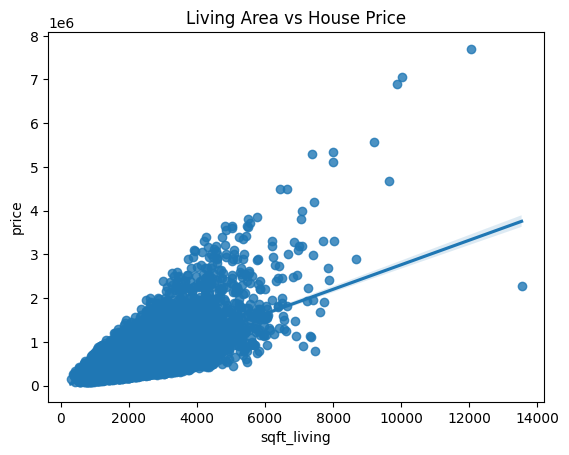

In [4]:
sns.regplot(data=df, x='sqft_living', y='price')
plt.title('Living Area vs House Price')
plt.show()

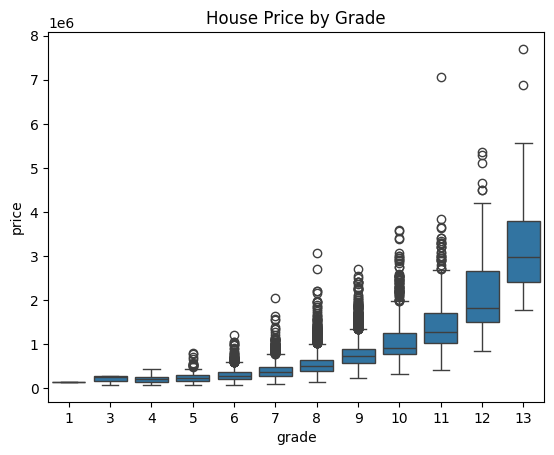

In [5]:
sns.boxplot(data=df, x='grade', y='price')
plt.title('House Price by Grade')
plt.show()

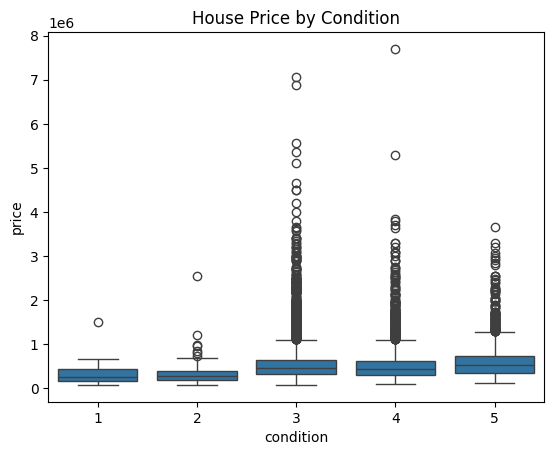

In [6]:
sns.boxplot(data=df, x='condition', y='price')
plt.title('House Price by Condition')
plt.show()

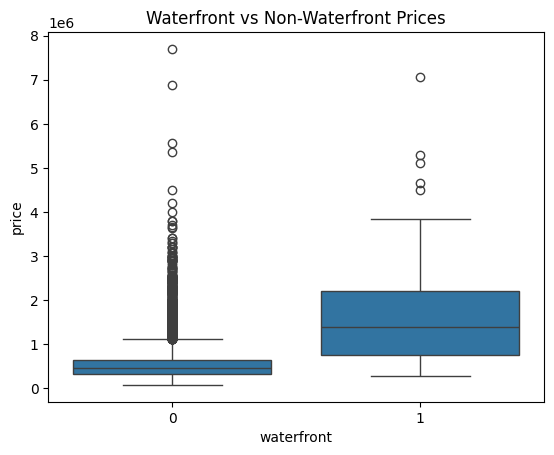

In [7]:
sns.boxplot(data=df, x='waterfront', y='price')
plt.title('Waterfront vs Non-Waterfront Prices')
plt.show()

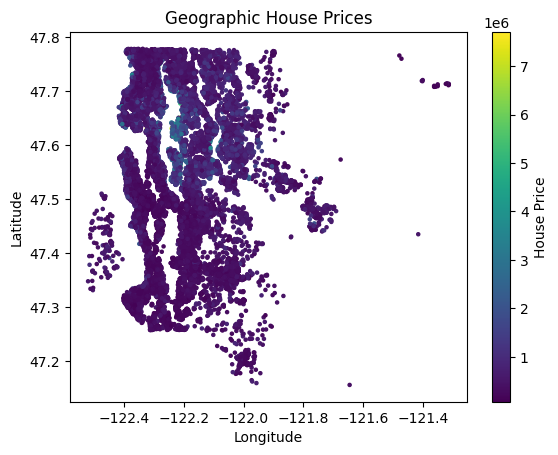

In [8]:
plt.scatter(df['long'], df['lat'], c=df['price'], cmap='viridis', s=5)
plt.colorbar(label='House Price')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Geographic House Prices')
plt.show()

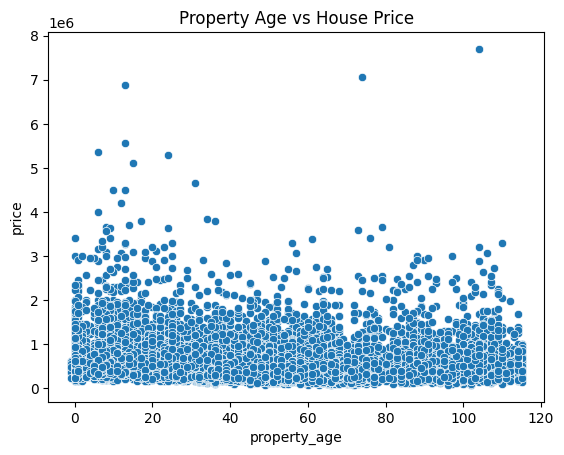

In [12]:
df['sale_year'] = pd.to_datetime(df['date']).dt.year
df['property_age'] = df['sale_year'] - df['yr_built']

sns.scatterplot(data=df, x='property_age', y='price')
plt.title('Property Age vs House Price')
plt.show()

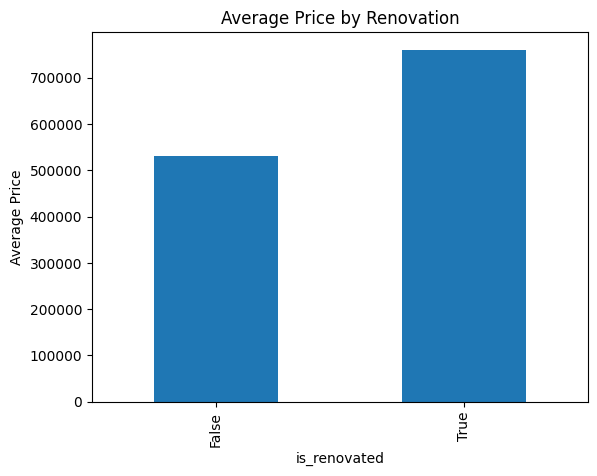

In [14]:
df['is_renovated'] = df['yr_renovated'] > 0

df.groupby('is_renovated')['price'].mean().plot(kind='bar')
plt.title('Average Price by Renovation')
plt.ylabel('Average Price')
plt.show()

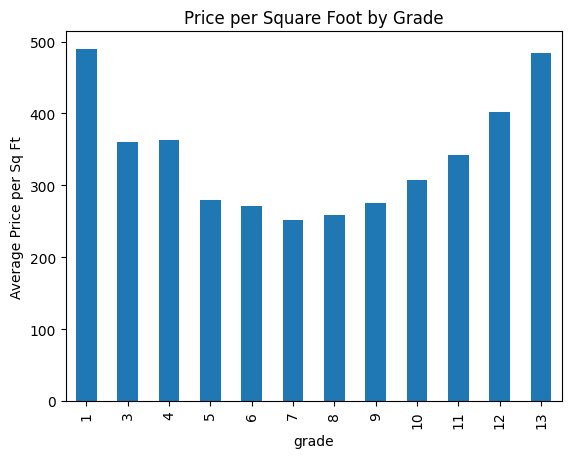

In [17]:
df['price_per_sqft_living'] = df['price'] / df['sqft_living']

df.groupby('grade')['price_per_sqft_living'].mean().plot(kind='bar')
plt.title('Price per Square Foot by Grade')
plt.ylabel('Average Price per Sq Ft')
plt.show()

In [18]:
print("Average House Price by Waterfront:")
print(df.groupby('waterfront')['price'].mean())

print("\nAverage House Price by Grade:")
print(df.groupby('grade')['price'].mean())

print("\nAverage House Price by Condition:")
print(df.groupby('condition')['price'].mean())

Average House Price by Waterfront:
waterfront
0    5.315636e+05
1    1.661876e+06
Name: price, dtype: float64

Average House Price by Grade:
grade
1     1.420000e+05
3     2.056667e+05
4     2.143810e+05
5     2.485240e+05
6     3.019196e+05
7     4.025903e+05
8     5.428528e+05
9     7.735132e+05
10    1.071771e+06
11    1.496842e+06
12    2.191222e+06
13    3.709615e+06
Name: price, dtype: float64

Average House Price by Condition:
condition
1    334431.666667
2    327287.145349
3    542012.578148
4    521200.390033
5    612418.089359
Name: price, dtype: float64
